# ЛР 9. Отчёт, который можно прочитать без кода

**Сущность:** Связать структуры, подписанные числовые признаки и статус решения в автономном отчёте.

**Данные:** molecules.csv; признаки и изображения рассчитываются заново.

**Workflow:** ID → 2D-сетка → график MW/TPSA → CSV → HTML с ограничениями.

Перед запуском прочитайте [guideline](../guides/lab09.md) и [теорию](../../Module_theory/Module%209_Visualization.md).

## 1. Прогноз

Запишите ожидаемое поведение и отрицательный контроль. Какое изменение входа должно изменить результат, а какое — сохранить?

In [1]:
from pathlib import Path
import sys, json, math, csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# WHY: relative discovery makes the notebook portable across machines.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Labs" / "chemistry.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запустите notebook внутри репозитория курса")
sys.path.insert(0, str(ROOT / "Labs"))
DATA = ROOT / "Labs" / "datasets"
OUT = ROOT / "Labs" / "results" / "lab09"
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()


## 2. Разбор и исполнение

1. Соберите структуры с подписями ID.
2. Постройте MW/TPSA с единицами; не называйте область графика областью эффективности.
3. Сохраните картинки и автономный HTML с таблицей и текстовым выводом.

Ожидаемое: В отчёте 12 строк включая ошибки, 10 валидных структур; картинки и относительные ссылки существуют.

[11:58:49] Initializing MetalDisconnector
[11:58:49] Running MetalDisconnector
[11:58:49] Initializing Normalizer
[11:58:49] Running Normalizer
[11:58:49] Initializing MetalDisconnector
[11:58:49] Running MetalDisconnector
[11:58:49] Initializing Normalizer
[11:58:49] Running Normalizer
[11:58:49] Running LargestFragmentChooser
[11:58:49] Running Uncharger
[11:58:49] Initializing MetalDisconnector
[11:58:49] Running MetalDisconnector
[11:58:49] Initializing Normalizer
[11:58:49] Running Normalizer
[11:58:49] Initializing MetalDisconnector
[11:58:49] Running MetalDisconnector
[11:58:49] Initializing Normalizer
[11:58:49] Running Normalizer
[11:58:49] Running LargestFragmentChooser
[11:58:49] Running Uncharger
[11:58:49] Initializing MetalDisconnector
[11:58:49] Running MetalDisconnector
[11:58:49] Initializing Normalizer
[11:58:49] Running Normalizer
[11:58:49] Initializing MetalDisconnector
[11:58:49] Running MetalDisconnector
[11:58:49] Initializing Normalizer
[11:58:49] Running Norma

[11:58:50] Initializing MetalDisconnector
[11:58:50] Running MetalDisconnector
[11:58:50] Initializing Normalizer
[11:58:50] Running Normalizer
[11:58:50] Initializing MetalDisconnector
[11:58:50] Running MetalDisconnector
[11:58:50] Initializing Normalizer
[11:58:50] Running Normalizer
[11:58:50] Running LargestFragmentChooser
[11:58:50] Running Uncharger


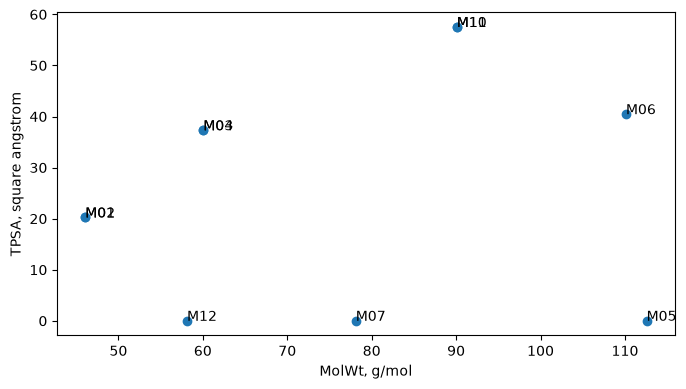

In [2]:
from chemistry import screen,parse
from rdkit.Chem import Draw
raw=pd.read_csv(DATA/"molecules.csv",keep_default_na=False)
table=pd.DataFrame([{"id":r.id,**screen(r.smiles)} for r in raw.itertuples()])
valid=table[table.status!="invalid"]
image=Draw.MolsToGridImage([parse(s) for s in valid.parent_smiles],molsPerRow=3,subImgSize=(260,180),legends=list(valid.id),returnPNG=False)
image.save(str(OUT/"structures.png"))
plt.figure(figsize=(7,4));plt.scatter(valid.MolWt,valid.TPSA)
for row in valid.itertuples(): plt.annotate(row.id,(row.MolWt,row.TPSA))
plt.xlabel("MolWt, g/mol");plt.ylabel("TPSA, square angstrom")
plt.tight_layout();plt.savefig(OUT/"properties.png",dpi=150);plt.show()
html="<meta charset='utf-8'><h1>Отчёт Химера</h1><p>Признаки parent, не доказательство активности.</p><img src='structures.png' width='800'><img src='properties.png' width='700'>"+table.to_html(index=False,escape=True)
(OUT/"report.html").write_text(html,encoding="utf-8")
assert len(table)==12
assert len(valid)==10
assert (OUT/"structures.png").exists() and (OUT/"report.html").exists()
artifact={"report":"report.html","rows":12,"structures":10}


## 3. Проверяемая запись запуска

Benchmark фиксирует этот запуск. Время включает расчёт и создание артефактов, но не установку среды; это не сравнительный рейтинг оборудования.

In [3]:
elapsed = time.perf_counter()-started
run_record = {"lab": 9, "calculation_wall_seconds": elapsed, "result": artifact}
(OUT/"benchmark.json").write_text(json.dumps(run_record,ensure_ascii=False,indent=2),encoding="utf-8")
print("Запуск сохранён:",OUT/"benchmark.json")


Запуск сохранён: C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\tmp\practice-audit-issue1-20261117\Labs\results\lab09\benchmark.json


## 4. Самостоятельная тренировка

1. Добавьте к точке ID и предупреждение.
2. Найдите вводящую в заблуждение подпись «drug-ready» и перепишите её.
3. Сформулируйте ограничение одной 3D-конформации.

[Ответы после попытки](../solutions/lab09.md). Вернитесь к первому заданию через неделю.

## 5. Ваш научный вывод

1. Какой результат получен?
2. Какой вывод из него пока не следует?
3. Какой следующий эксперимент или контроль нужен?

Сохраните свой вариант notebook отдельно; исходный пример должен остаться воспроизводимым.